# Custom component: load it, wire it into the reference graph, manipulate the signal

The example component `example_component` (file `examples/components/example_component.py`, model doc `docs/model/example-component.md`) is an electrical gain and delay block, $H(f) = g\,e^{-j2\pi f\tau}$. With its defaults ($g = 1$, $\tau = 0$) $H(f) = 1$. This notebook loads it from its file, inserts it into the reference graph between the receive filter `rxf` and the FFE, and changes the signal step by step.

In [1]:
import importlib.util
import numpy as np
import matplotlib.pyplot as plt
import lightstone

# Load the component from its file. Importing the module only creates the Component object;
# it is handed to the graph below (components=[...] or g.use(...)).
spec = importlib.util.spec_from_file_location("example_component", "../examples/components/example_component.py")
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
mod.example_component

Component('example_component', linear=True, domain='frequency', function)

## 1. The reference graph as it is

In [2]:
g = lightstone.Graph.reference()
print(g.nodes())
for w in g.config["wires"]:
    print(f"  {w['from']:8s} → {w['to']}")
g.run()
base = g.receiver()
a0 = base.analyze()
print(f"SER {a0['ser']:.2e}, eye heights {np.round(np.array(a0['eye_height']) * 1e3, 1)} mV")

['src', 'drv', 'vcsel', 'el0', 'el1', 'pin', 'tia', 'rxf', 'ffe', 'rx']
  src.out  → drv.in
  drv.out  → vcsel.in
  vcsel.out → el0.in
  el0.out  → el1.in
  el1.out  → pin.in
  pin.out  → tia.in
  tia.out  → rxf.in
  rxf.out  → ffe.in
  src.out  → ffe.ref
  ffe.out  → rx.in
SER 1.86e-07, eye heights [78.1 70.8 61.3] mV


## 2. Rewire: insert the example component between `rxf` and `ffe`

`insert("ffe", ...)` cuts the wire into `ffe.in` and puts the new node in it: `rxf → ex → ffe`. With $H(f) = 1$ the receiver output is bit-identical to the reference graph.

In [3]:
g.use(mod.example_component).insert("ffe", "ex", "example_component")
for w in g.config["wires"]:
    if "ex" in (w["from"].split(".")[0], w["to"].split(".")[0]):
        print(f"  {w['from']:8s} → {w['to']}")
g.run()
r = g.receiver()
print("max |Δ signal| =", np.max(np.abs(r.signal - base.signal)), " max |Δ σ| =", np.max(np.abs(r.sigma - base.sigma)))
print("SER", r.analyze()["ser"], "(nodes computed:", g.computed_last_run, "— all, because a new kind was registered)")

  ex.out   → ffe.in
  rxf.out  → ex.in
max |Δ signal| = 0.0  max |Δ σ| = 0.0
SER 1.857571420411732e-07 (nodes computed: 11 — all, because a new kind was registered)


## 3. Gain: $g = 0.5$

The block is linear, so Lightstone scales the signal **and** every noise term by $g$. The eye halves, the SER does not change. Only `ex`, `ffe` and `rx` are recomputed.

SER 1.86e-07, eye heights [39.1 35.4 30.7] mV, nodes computed: 3


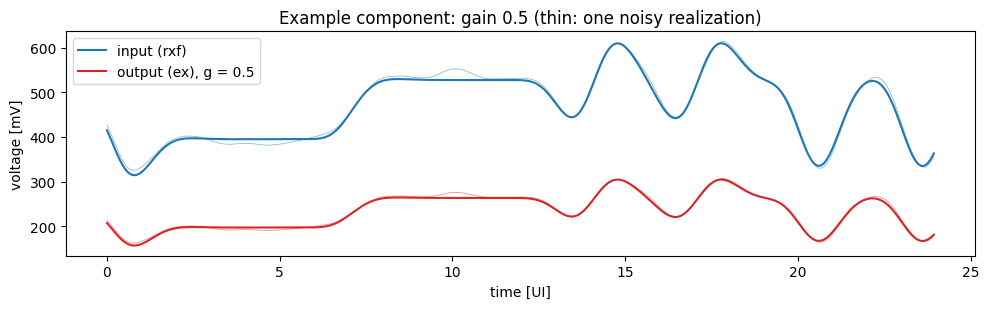

In [4]:
def snippet(g, node, n_sym=24):
    o = g.output(node)
    sps = g.settings["sps"]
    t = np.arange(n_sym * sps) / sps
    return t, o["noiseless"][: n_sym * sps], o["signal"][: n_sym * sps]

g.set("ex", gain=0.5).run()
a = g.receiver().analyze()
print(f"SER {a['ser']:.2e}, eye heights {np.round(np.array(a['eye_height']) * 1e3, 1)} mV, nodes computed: {g.computed_last_run}")
fig, ax = plt.subplots(figsize=(10, 3.2))
for node, lab, col in (("rxf", "input (rxf)", "C0"), ("ex", "output (ex), g = 0.5", "C3")):
    t, y0, y = snippet(g, node)
    ax.plot(t, y * 1e3, lw=0.6, alpha=0.5, color=col)
    ax.plot(t, y0 * 1e3, lw=1.5, color=col, label=lab)
ax.set(xlabel="time [UI]", ylabel="voltage [mV]", title="Example component: gain 0.5 (thin: one noisy realization)")
ax.legend(); plt.tight_layout()

## 4. Delay: $\tau = 0.25$ UI

A pure delay shifts the waveform. The analysis finds the new symbol alignment by itself, so the SER is the same; the alignment delay grows by 0.25 UI × 16 samples/UI = 4 samples.

SER 1.86e-07; alignment delay 19 → 23 samples


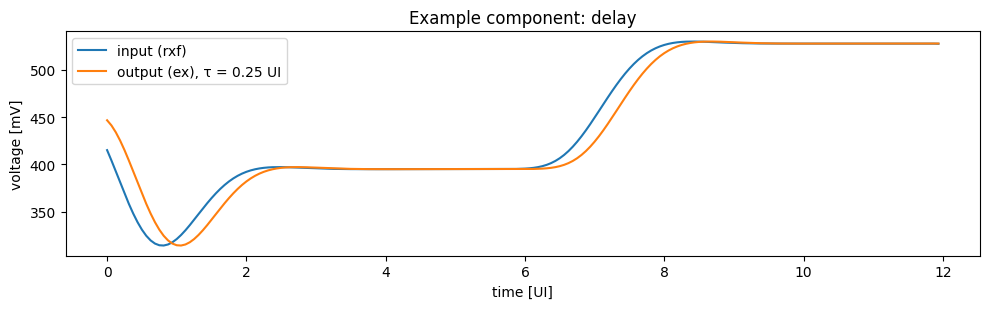

In [5]:
T = 1 / g.settings["baud"]
g.set("ex", gain=1.0, delay=0.25 * T).run()
a = g.receiver().analyze()
print(f"SER {a['ser']:.2e}; alignment delay {a0['delay']} → {a['delay']} samples")
fig, ax = plt.subplots(figsize=(10, 3.2))
for node, lab in (("rxf", "input (rxf)"), ("ex", "output (ex), τ = 0.25 UI")):
    t, y0, _ = snippet(g, node, 12)
    ax.plot(t, y0 * 1e3, lw=1.5, label=lab)
ax.set(xlabel="time [UI]", ylabel="voltage [mV]", title="Example component: delay"); ax.legend(); plt.tight_layout()

## 5. Change H(f): from gain block to a CTLE that replaces the FFE

A new kind reuses the example's transfer function and multiplies it by one zero and one pole, $H(f) = g\,e^{-j2\pi f\tau}\,(1 + jf/f_z)/(1 + jf/f_p)$: a continuous-time linear equalizer (CTLE) with DC gain $g$ and high-frequency boost $f_p/f_z$. It goes into the reference link **without** its FFE (`rxf → ctle → rx`). Without any equalizer the 100 m eye is closed (SER ≈ 0.10).

no equalizer: SER 9.95e-02;  CTLE (fz 12 GHz, fp 40 GHz): SER 2.50e-04


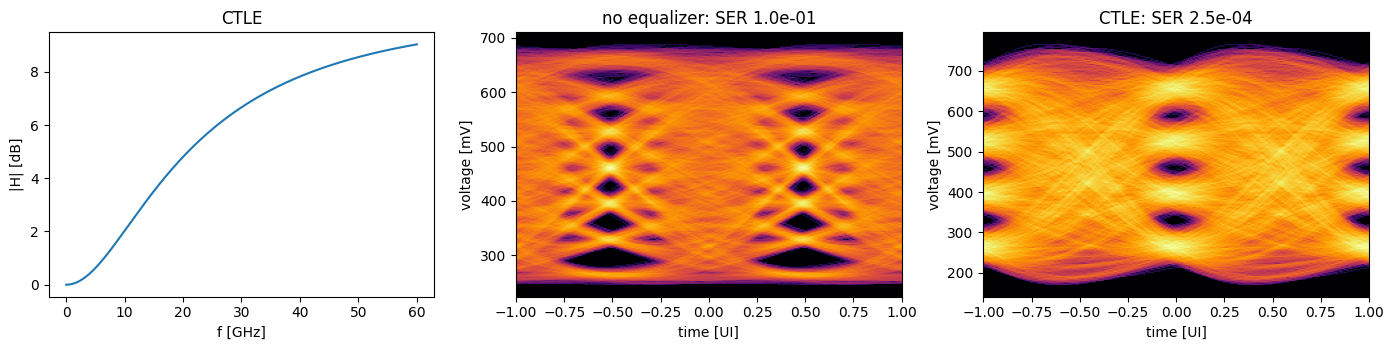

In [6]:
def ctle(f, ctx):
    fz, fp = ctx.params.get("fz", 12e9), ctx.params.get("fp", 40e9)
    return mod.transfer(f, ctx) * (1 + 1j * f / fz) / (1 + 1j * f / fp)

example_ctle = lightstone.Component("example_ctle", inputs={"in": "electrical"}, outputs={"out": "electrical"},
                                    linear=True, domain="frequency", function=ctle)

h = lightstone.Graph.reference({"rx": {"ffe_taps": 0}}, components=[example_ctle]).run()
eq0 = h.receiver(); s0 = eq0.analyze()
h.insert("rx", "ctle", "example_ctle", fz=12e9, fp=40e9).run()
eq1 = h.receiver(); s1 = eq1.analyze()
print(f"no equalizer: SER {s0['ser']:.2e};  CTLE (fz 12 GHz, fp 40 GHz): SER {s1['ser']:.2e}")

f = np.linspace(0, 60e9, 600)
class Ctx:  # minimal stand-in for the simulation context, to plot H(f)
    params = {"fz": 12e9, "fp": 40e9}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(f / 1e9, 20 * np.log10(np.abs(ctle(f, Ctx)))); ax[0].set(xlabel="f [GHz]", ylabel="|H| [dB]", title="CTLE")
for k, (rx, s, lab) in enumerate(((eq0, s0, "no equalizer"), (eq1, s1, "CTLE"))):
    counts, meta = rx.eye(300, 200, analysis=s)
    ax[k + 1].imshow(np.log1p(counts), aspect="auto", cmap="inferno",
                     extent=[-1, 1, meta["v_min"] * 1e3, meta["v_max"] * 1e3])
    ax[k + 1].set(xlabel="time [UI]", ylabel="voltage [mV]", title=f"{lab}: SER {s['ser']:.1e}")
plt.tight_layout()

The CTLE opens the eye (SER from about 0.10 to about 2.5 × 10⁻⁴); the adaptive 5-tap FFE of the reference link reaches 1.9 × 10⁻⁷. Because both blocks are linear, the noise stays Gaussian and exact, and the SER is still semi-analytic. In both eyes the sampling point is at 0 UI. The dark diamonds at ±0.5 UI of the unequalized eye are gaps between traces that ISI has split apart, not the three PAM-4 eyes; the analyzer's SER is lowest at 0 UI. Try other $f_z$, $f_p$ with `h.set("ctle", fz=..., fp=...).run()`.